In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load prepared dataset
df = pd.read_csv(
    "../data/daily_food_sales.csv",
    parse_dates=["date"]
)

df = df.sort_values("day_number").reset_index(drop=True)

# Create lag features
for lag in [1, 7, 14, 28]:
    df[f"lag_{lag}"] = df["units_sold"].shift(lag)

# Create rolling features using previous days only
df["rolling_mean_7"] = (
    df["units_sold"].shift(1).rolling(7).mean()
)

df["rolling_mean_28"] = (
    df["units_sold"].shift(1).rolling(28).mean()
)

# Calendar features
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

# Drop rows without sufficient historical data
df = df.dropna(subset=[
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
])

print(df.head())
print("Rows available:", len(df))


       d  units_sold  day_number       date  prediction    weekday   lag_1  \
28  d_29        2574          29 2011-02-26      3148.0   Saturday  1875.0   
29  d_30        2733          30 2011-02-27      2864.0     Sunday  2574.0   
30  d_31        1732          31 2011-02-28      2105.0     Monday  2733.0   
31  d_32        1896          32 2011-03-01      1621.0    Tuesday  1732.0   
32  d_33        1965          33 2011-03-02      1608.0  Wednesday  1896.0   

     lag_7  lag_14  lag_28  rolling_mean_7  rolling_mean_28  day_of_week  \
28  3148.0  3067.0  3239.0     2122.857143      2373.857143            5   
29  2864.0  3313.0  3137.0     2040.857143      2350.107143            6   
30  2105.0  2003.0  2008.0     2022.142857      2335.678571            0   
31  1621.0  1779.0  2258.0     1968.857143      2325.821429            1   
32  1608.0  1670.0  2032.0     2008.142857      2312.892857            2   

    month  
28      2  
29      2  
30      2  
31      3  
32      3  
Ro

In [2]:

# Define features and target
numeric_features = [
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

categorical_features = ["day_of_week", "month"]

features = numeric_features + categorical_features
target = "units_sold"

# Chronological split
train = df[df["day_number"] <= 1773].copy()

validation = df[
    df["day_number"].between(1774, 1829)
].copy()

X_train = train[features]
y_train = train[target]

X_val = validation[features]
y_val = validation[target]

print("Training rows:", len(train))
print("Validation rows:", len(validation))


Training rows: 1745
Validation rows: 56


In [3]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# ML pipeline
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

# Train model
ridge_model.fit(X_train, y_train)

# Predict validation period
ridge_predictions = ridge_model.predict(X_val)

print("Ridge Regression successfully trained!")


Ridge Regression successfully trained!


In [4]:

from sklearn.metrics import mean_absolute_error

# Seasonal naive predictions
naive_predictions = validation["lag_7"]

# MAE
naive_mae = mean_absolute_error(y_val, naive_predictions)
ridge_mae = mean_absolute_error(y_val, ridge_predictions)

# WAPE
naive_wape = (
    np.abs(y_val - naive_predictions).sum()
    / y_val.abs().sum() * 100
)

ridge_wape = (
    np.abs(y_val - ridge_predictions).sum()
    / y_val.abs().sum() * 100
)

print("SEASONAL NAIVE")
print(f"MAE: {naive_mae:.2f}")
print(f"WAPE: {naive_wape:.2f}%")

print("\nRIDGE REGRESSION")
print(f"MAE: {ridge_mae:.2f}")
print(f"WAPE: {ridge_wape:.2f}%")

improvement = (naive_mae - ridge_mae) / naive_mae * 100

print(f"\nMAE improvement: {improvement:.2f}%")


SEASONAL NAIVE
MAE: 369.96
WAPE: 14.14%

RIDGE REGRESSION
MAE: 258.77
WAPE: 9.89%

MAE improvement: 30.05%


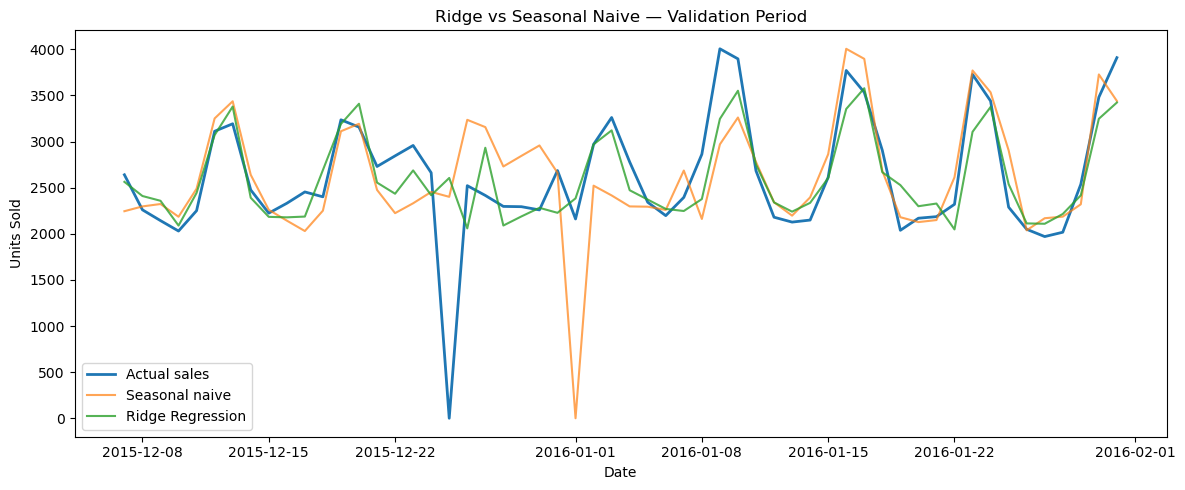

In [5]:

plt.figure(figsize=(12, 5))

plt.plot(
    validation["date"],
    y_val,
    label="Actual sales",
    linewidth=2
)

plt.plot(
    validation["date"],
    naive_predictions,
    label="Seasonal naive",
    alpha=0.7
)

plt.plot(
    validation["date"],
    ridge_predictions,
    label="Ridge Regression",
    alpha=0.8
)

plt.title("Ridge vs Seasonal Naive — Validation Period")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()


In [6]:

# Create an error analysis table
error_analysis = validation[
    ["date", "units_sold"]
].copy()

error_analysis["ridge_prediction"] = ridge_predictions
error_analysis["naive_prediction"] = naive_predictions

error_analysis["ridge_error"] = abs(
    error_analysis["units_sold"]
    - error_analysis["ridge_prediction"]
)

error_analysis["naive_error"] = abs(
    error_analysis["units_sold"]
    - error_analysis["naive_prediction"]
)

# Show the 10 largest Ridge errors
print(
    error_analysis.nlargest(10, "ridge_error").to_string(index=False)
)


      date  units_sold  ridge_prediction  naive_prediction  ridge_error  naive_error
2015-12-25           0       2605.531161            2401.0  2605.531161       2401.0
2016-01-09        4006       3246.184632            2970.0   759.815368       1036.0
2016-01-23        3728       3105.398807            3771.0   622.601193         43.0
2015-12-27        2416       2933.099139            3157.0   517.099139        741.0
2016-01-19        2038       2528.130471            2180.0   490.130471        142.0
2016-01-31        3910       3423.355929            3440.0   486.644071        470.0
2016-01-08        2863       2376.889209            2161.0   486.110791        702.0
2015-12-26        2522       2058.969631            3236.0   463.030369        714.0
2015-12-31        2686       2227.593129            2662.0   458.406871         24.0
2016-01-16        3771       3353.713414            4006.0   417.286586        235.0


In [7]:

# Load additional calendar information
calendar_events = pd.read_csv(
    "../data/raw/calendar.csv",
    usecols=[
        "d",
        "event_name_1",
        "event_name_2"
    ]
)

# Merge with our existing forecasting dataset
df_events = df.merge(
    calendar_events,
    on="d",
    how="left",
    validate="many_to_one"
)

# Replace missing event names with an explicit category
df_events["event_name_1"] = (
    df_events["event_name_1"].fillna("No_Event")
)

df_events["event_name_2"] = (
    df_events["event_name_2"].fillna("No_Event")
)

# Add the new categorical predictors
event_features = categorical_features + [
    "event_name_1",
    "event_name_2"
]

all_features = numeric_features + event_features

# Keep our original validation boundaries
train_events = df_events[
    df_events["day_number"] <= 1773
]

validation_events = df_events[
    df_events["day_number"].between(1774, 1829)
]

# Rebuild preprocessing
event_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         event_features)
    ]
)

# Train the updated Ridge model
ridge_events = Pipeline([
    ("preprocessor", event_preprocessor),
    ("model", Ridge(alpha=10.0))
])

ridge_events.fit(
    train_events[all_features],
    train_events["units_sold"]
)

event_predictions = ridge_events.predict(
    validation_events[all_features]
)

# Compare model performance
event_mae = mean_absolute_error(
    validation_events["units_sold"],
    event_predictions
)

print(f"Original Ridge MAE: {ridge_mae:.2f}")
print(f"Ridge + Events MAE: {event_mae:.2f}")

print(
    f"Change in MAE: {ridge_mae - event_mae:.2f} units"
)


Original Ridge MAE: 258.77
Ridge + Events MAE: 247.37
Change in MAE: 11.41 units


In [8]:

christmas_sales = df_events[
    (df_events["date"].dt.month == 12) &
    (df_events["date"].dt.day == 25)
]

print(
    christmas_sales[
        ["date", "units_sold",
         "event_name_1", "event_name_2"]
    ].to_string(index=False)
)


      date  units_sold event_name_1 event_name_2
2011-12-25           0    Christmas     No_Event
2012-12-25           0    Christmas     No_Event
2013-12-25           0    Christmas     No_Event
2014-12-25           0    Christmas     No_Event
2015-12-25           0    Christmas     No_Event


In [9]:

comparison = validation_events[
    ["date", "units_sold"]
].copy()

comparison["original_ridge"] = ridge_predictions
comparison["ridge_events"] = event_predictions

print(
    comparison[
        comparison["date"] == "2015-12-25"
    ].to_string(index=False)
)


      date  units_sold  original_ridge  ridge_events
2015-12-25           0     2605.531161    1740.73795
